# Clase Taller: Machine Learning con vibraciones de motores

**Caso:** diagnóstico del estado de un rodamiento a partir de señales de vibración.

**Dataset:** Case Western Reserve University (CWRU) Bearing Data Center.

En esta práctica construiremos un flujo completo de Machine Learning:

1. Comprender el problema físico.
2. Descargar señales reales de vibración.
3. Visualizar la señal en el dominio del tiempo.
4. Observar su contenido en frecuencia mediante FFT.
5. Segmentar la señal en ventanas.
6. Extraer características físicas y estadísticas.
7. Construir un dataset tabular.
8. Entrenar un clasificador.
9. Evaluar el modelo con matriz de confusión y métricas.
10. Interpretar qué características fueron más importantes.

> **Objetivo didáctico:** comprender cómo una señal de sensor se transforma en variables útiles para un modelo de clasificación.

## 1. Contexto del problema

Un motor eléctrico en funcionamiento produce vibraciones.  
Cuando aparecen defectos mecánicos —por ejemplo, en un rodamiento— cambia el patrón de vibración.

Un acelerómetro registra una señal:

x(t) = 	aceleración medida a lo largo del tiempo

El problema de Machine Learning será:

señal de vibración -> características -> estado del rodamiento

Trabajaremos con cuatro clases:

- `Normal`
- `InnerRace` — defecto en pista interior
- `OuterRace` — defecto en pista exterior
- `Ball` — defecto en elemento rodante

Para simplificar la clase utilizaremos archivos a **12 kHz** y con condiciones comparables.

## 2. Importar bibliotecas

La práctica usa únicamente bibliotecas disponibles en Google Colab.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
FS = 12000  # frecuencia de muestreo, Hz

## 3. Descargar una muestra didáctica del dataset CWRU

Usaremos cuatro registros:

| Clase | Archivo |
|---|---:|
| Normal | 97.mat |
| Pista interior | 105.mat |
| Elemento rodante | 118.mat |
| Pista exterior | 130.mat |

El código intenta descargar directamente los archivos desde el sitio de Case Western Reserve University.

Si en algún momento el servidor oficial cambia la ruta, puede descargarse manualmente el archivo desde el **Bearing Data Center** y subirlo a Colab.

In [2]:
import urllib.request

os.makedirs("cwru_data", exist_ok=True)

files = {
    "Normal": "97.mat",
    "InnerRace": "105.mat",
    "Ball": "118.mat",
    "OuterRace": "130.mat"
}

BASE_URL = "https://engineering.case.edu/sites/default/files/"

for label, filename in files.items():
    path = os.path.join("cwru_data", filename)
    if not os.path.exists(path):
        url = BASE_URL + filename
        print(f"Descargando {label}: {url}")
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as e:
            print(f"No se pudo descargar automáticamente {filename}: {e}")
    else:
        print(f"{filename} ya existe.")

97.mat ya existe.
105.mat ya existe.
118.mat ya existe.
130.mat ya existe.


### Verificación

Antes de continuar comprobamos que los archivos estén disponibles.

In [3]:
for label, filename in files.items():
    path = os.path.join("cwru_data", filename)
    print(label, "->", path, "| existe:", os.path.exists(path))

Normal -> cwru_data\97.mat | existe: True
InnerRace -> cwru_data\105.mat | existe: True
Ball -> cwru_data\118.mat | existe: True
OuterRace -> cwru_data\130.mat | existe: True


## 4. Inspeccionar un archivo `.mat`

Los registros originales están almacenados en formato MATLAB.

Cada archivo puede contener varias variables.  
Las variables cuyo nombre incluye `DE_time` corresponden a la señal del acelerómetro en el **Drive End** del motor.

In [4]:
example = loadmat("cwru_data/97.mat")

print("Variables disponibles:")
for k in example.keys():
    if not k.startswith("__"):
        arr = np.asarray(example[k])
        print(f"{k:20s} shape={arr.shape}")

Variables disponibles:
X097_DE_time         shape=(243938, 1)
X097_FE_time         shape=(243938, 1)
X097RPM              shape=(1, 1)


## 5. Función para extraer automáticamente la señal de vibración

En lugar de escribir el nombre exacto de la variable de cada archivo, buscamos la variable que contenga `DE_time`.

In [5]:
def load_de_signal(path):
    mat = loadmat(path)
    keys = [k for k in mat.keys() if "DE_time" in k]

    if len(keys) == 0:
        raise ValueError(f"No se encontró una variable DE_time en {path}")

    signal = np.asarray(mat[keys[0]]).squeeze()
    return signal.astype(float)

signals = {
    label: load_de_signal(os.path.join("cwru_data", filename))
    for label, filename in files.items()
}

for label, x in signals.items():
    print(f"{label:10s} -> {len(x):,} muestras")

Normal     -> 243,938 muestras
InnerRace  -> 121,265 muestras
Ball       -> 122,571 muestras
OuterRace  -> 121,991 muestras


## 6. Visualizar la señal en el dominio del tiempo

Pregunta:

> **¿Puede distinguirse visualmente una señal normal de una señal con falla?**

Mostraremos aproximadamente los primeros 0,15 segundos de cada registro.

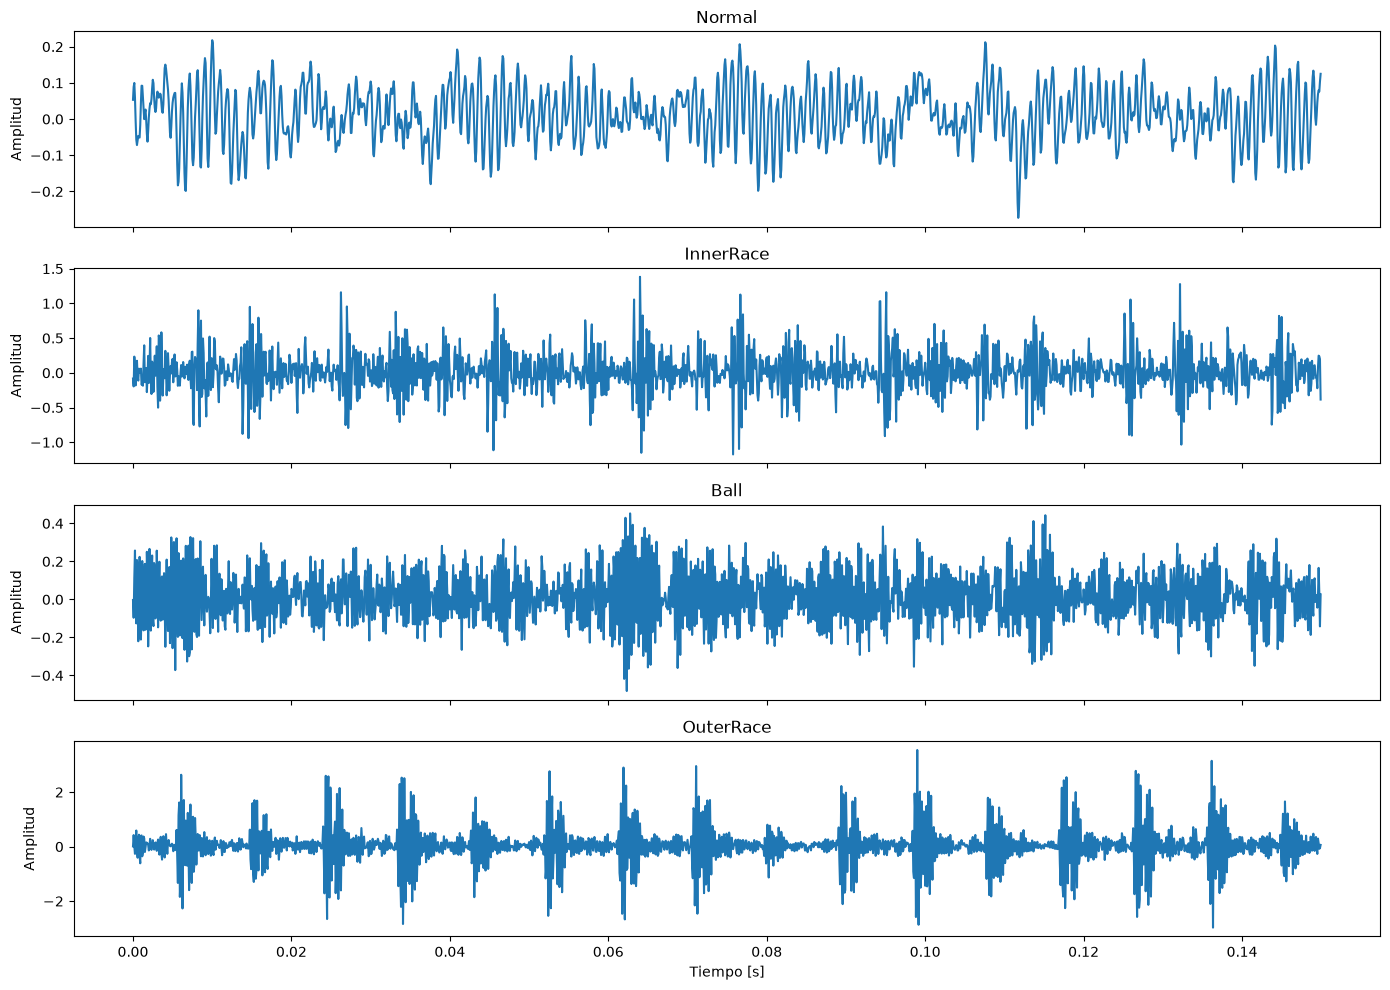

In [6]:
n_show = int(0.15 * FS)
t = np.arange(n_show) / FS

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

for ax, (label, x) in zip(axes, signals.items()):
    ax.plot(t, x[:n_show])
    ax.set_title(label)
    ax.set_ylabel("Amplitud")

axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

### Observar:

- amplitud,
- impulsos,
- repetitividad,
- variabilidad,
- diferencias entre las clases.

La señal cruda contiene mucha información, pero no está todavía en una forma cómoda para un algoritmo clásico de Machine Learning.

Por eso realizaremos **ingeniería de características**.

## 7. Mirar la señal en el dominio de la frecuencia

La Transformada Rápida de Fourier (FFT) permite representar la señal como amplitud en función de la frecuencia.

Esto es especialmente útil en maquinaria rotativa porque muchos defectos generan componentes periódicas.

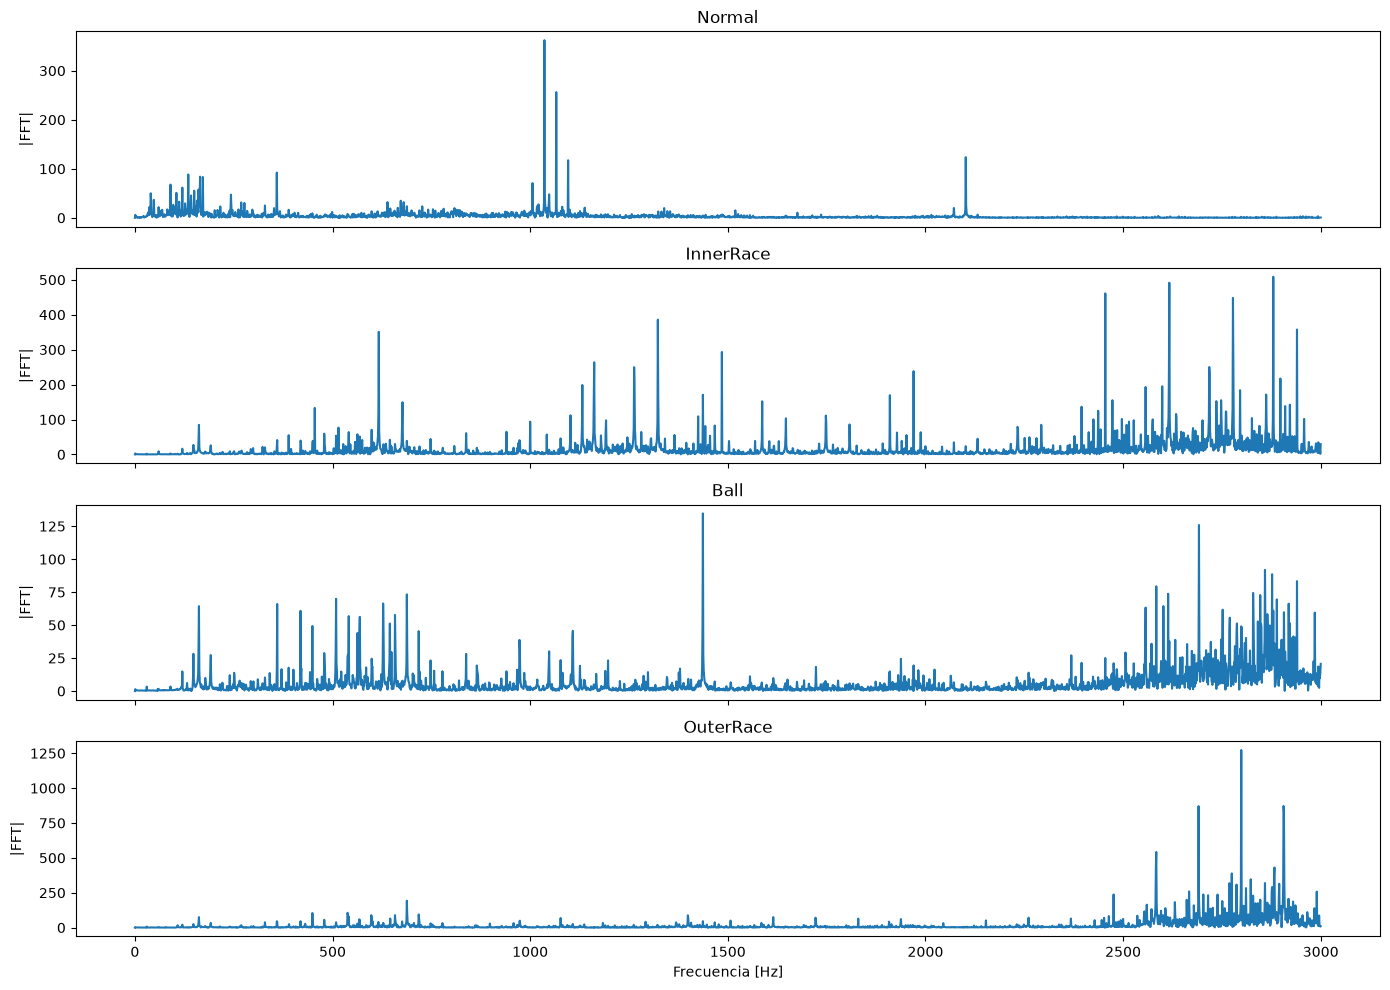

In [7]:
def plot_fft(signal, fs=FS, n_samples=12000, max_freq=3000):
    x = signal[:n_samples]
    x = x - np.mean(x)

    spectrum = np.abs(rfft(x))
    freqs = rfftfreq(len(x), d=1/fs)

    mask = freqs <= max_freq
    return freqs[mask], spectrum[mask]

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

for ax, (label, x) in zip(axes, signals.items()):
    f, a = plot_fft(x)
    ax.plot(f, a)
    ax.set_title(label)
    ax.set_ylabel("|FFT|")

axes[-1].set_xlabel("Frecuencia [Hz]")
plt.tight_layout()
plt.show()

## 8. Segmentar la señal en ventanas

Un único archivo contiene decenas o cientos de miles de muestras.

Para construir ejemplos de entrenamiento, dividiremos la señal en pequeñas ventanas de:

\[
N = 2048 	muestras
\]

A 12 kHz, cada ventana representa aproximadamente:

\[
2048 / 12000 approx 0.171 	segundos
\]

Cada ventana se convertirá en **una fila del dataset de Machine Learning**.

In [8]:
WINDOW_SIZE = 2048
STEP = 2048  # sin solapamiento para mantener la explicación simple

def segment_signal(signal, window_size=WINDOW_SIZE, step=STEP):
    windows = []
    for start in range(0, len(signal) - window_size + 1, step):
        windows.append(signal[start:start + window_size])
    return np.array(windows)

segmented = {label: segment_signal(x) for label, x in signals.items()}

for label, Xw in segmented.items():
    print(f"{label:10s}: {Xw.shape[0]} ventanas de {Xw.shape[1]} muestras")

Normal    : 119 ventanas de 2048 muestras
InnerRace : 59 ventanas de 2048 muestras
Ball      : 59 ventanas de 2048 muestras
OuterRace : 59 ventanas de 2048 muestras


## 9. Extraer características

En Machine Learning clásico no entregaremos directamente las 2048 muestras al clasificador.

Para cada ventana calcularemos un conjunto compacto de variables.

### Características temporales

- Media
- Desviación estándar
- RMS
- Pico absoluto
- Peak-to-peak
- Curtosis
- Asimetría
- Crest factor

El **RMS** es una medida de energía de la vibración:

$$
RMS = \sqrt{\frac{1}{N}\sum_{i=1}^{N} x_i^2}
$$


El **crest factor** compara el pico máximo con el RMS:

$$
CF = \frac{\max |x|}{RMS}
$$

La **curtosis** es especialmente útil para identificar señales impulsivas.

### Características frecuenciales

También extraeremos:

- frecuencia dominante,
- centroide espectral,
- energía espectral.

In [9]:
def extract_features(x, fs=FS):
    x = np.asarray(x)
    x_centered = x - np.mean(x)

    mean = np.mean(x)
    std = np.std(x)
    rms = np.sqrt(np.mean(x**2))
    peak = np.max(np.abs(x))
    peak_to_peak = np.ptp(x)
    kurt = kurtosis(x, fisher=False)
    sk = skew(x)
    crest_factor = peak / rms if rms > 0 else 0

    # FFT
    spec = np.abs(rfft(x_centered))
    freqs = rfftfreq(len(x), d=1/fs)
    power = spec**2

    # ignorar DC para la frecuencia dominante
    if len(spec) > 1:
        dominant_freq = freqs[1:][np.argmax(spec[1:])]
    else:
        dominant_freq = 0

    spectral_energy = np.sum(power)
    spectral_centroid = (
        np.sum(freqs * power) / np.sum(power)
        if np.sum(power) > 0 else 0
    )

    return {
        "mean": mean,
        "std": std,
        "rms": rms,
        "peak": peak,
        "peak_to_peak": peak_to_peak,
        "kurtosis": kurt,
        "skewness": sk,
        "crest_factor": crest_factor,
        "dominant_freq": dominant_freq,
        "spectral_centroid": spectral_centroid,
        "spectral_energy": spectral_energy
    }

## 10. Construir el dataset tabular

Ahora convertimos:

**ventana de señal → fila de características + etiqueta**

In [10]:
rows = []

for label, windows in segmented.items():
    for i, window in enumerate(windows):
        features = extract_features(window)
        features["label"] = label
        features["window_id"] = i
        rows.append(features)

df = pd.DataFrame(rows)

print("Dimensión del dataset:", df.shape)
df.head()

Dimensión del dataset: (296, 13)


,mean,std,rms,peak,peak_to_peak,kurtosis,skewness,crest_factor,dominant_freq,spectral_centroid,spectral_energy,label,window_id
0,0.012005,0.072266,0.073256,0.272869,0.490663,2.954176,-0.137322,3.724845,1037.109375,846.745199,10952.144381,Normal,0
1,0.012790,0.077993,0.079035,0.226765,0.449775,2.815420,-0.062348,2.869171,1037.109375,825.777556,12756.862158,Normal,1
2,0.011959,0.073370,0.074338,0.219255,0.421403,2.778240,0.025960,2.949440,1037.109375,878.032390,11289.154968,Normal,2
3,0.010285,0.072967,0.073688,0.249295,0.496713,2.930965,-0.147535,3.383105,1037.109375,885.308671,11165.651093,Normal,3
4,0.011016,0.071265,0.072112,0.224679,0.428287,2.794399,-0.083451,3.115698,1037.109375,902.122732,10650.929395,Normal,4


## 11. Explorar el dataset de características

Cada fila es ahora una observación de Machine Learning.

In [11]:
df.groupby("label").size()

label
Ball          59
InnerRace     59
Normal       119
OuterRace     59
dtype: int64

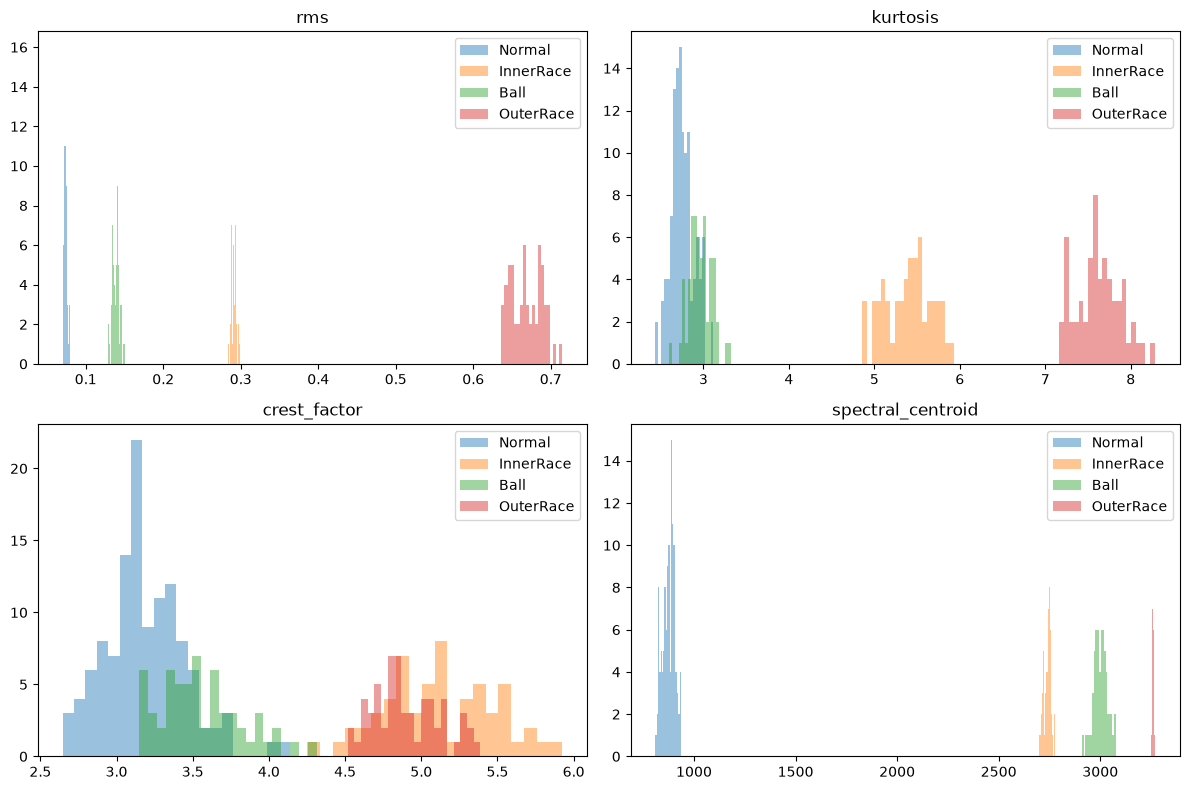

In [12]:
features_to_plot = ["rms", "kurtosis", "crest_factor", "spectral_centroid"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.ravel(), features_to_plot):
    for label in df["label"].unique():
        values = df.loc[df["label"] == label, feature]
        ax.hist(values, bins=20, alpha=0.45, label=label)
    ax.set_title(feature)
    ax.legend()

plt.tight_layout()
plt.show()

### Pregunta:

> ¿Qué características parecen separar mejor las clases?

Esta pregunta conecta el análisis exploratorio con la idea de **frontera de decisión**.

## 12. Preparar X e y

- `X`: variables predictoras
- `y`: clase que queremos predecir

In [13]:
feature_cols = [
    "mean", "std", "rms", "peak", "peak_to_peak",
    "kurtosis", "skewness", "crest_factor",
    "dominant_freq", "spectral_centroid", "spectral_energy"
]

X = df[feature_cols]
y = df["label"]

print("X:", X.shape)
print("y:", y.shape)

X: (296, 11)
y: (296,)


## 13. Dividir entrenamiento y prueba

Separamos los datos en:

- 70 % entrenamiento
- 30 % prueba

Usamos `stratify=y` para conservar aproximadamente la proporción de clases.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (207, 11)
Prueba: (89, 11)


## 14. Modelo 1 — Regresión logística

Aunque su nombre diga “regresión”, puede utilizarse para clasificación.

Antes de entrenarla estandarizamos las variables porque sus escalas son muy diferentes.

In [15]:
log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000))
])

log_model.fit(X_train, y_train)

pred_log = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_log))
print()
print(classification_report(y_test, pred_log))

Accuracy: 1.0

              precision    recall  f1-score   support

        Ball       1.00      1.00      1.00        17
   InnerRace       1.00      1.00      1.00        18
      Normal       1.00      1.00      1.00        36
   OuterRace       1.00      1.00      1.00        18

    accuracy                           1.00        89
   macro avg       1.00      1.00      1.00        89
weighted avg       1.00      1.00      1.00        89



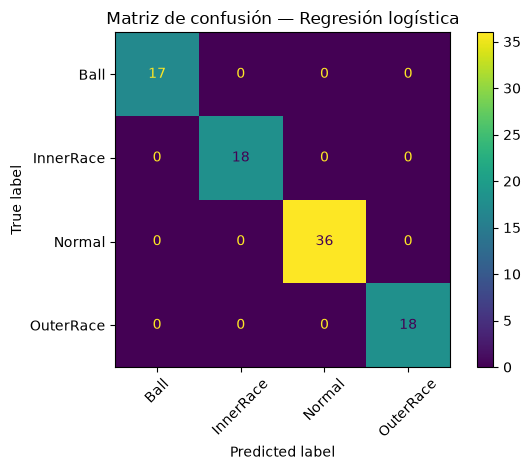

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_log,
    xticks_rotation=45
)
plt.title("Matriz de confusión — Regresión logística")
plt.tight_layout()
plt.show()

## 15. Modelo 2 — Random Forest

Random Forest combina muchos árboles de decisión.

Ventajas para una práctica introductoria:

- funciona bien con relaciones no lineales,
- no requiere normalización,
- permite estimar importancia de variables,
- es relativamente fácil de interpretar.

In [17]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE
)

rf_model.fit(X_train, y_train)

pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_rf))
print()
print(classification_report(y_test, pred_rf))

Accuracy: 1.0

              precision    recall  f1-score   support

        Ball       1.00      1.00      1.00        17
   InnerRace       1.00      1.00      1.00        18
      Normal       1.00      1.00      1.00        36
   OuterRace       1.00      1.00      1.00        18

    accuracy                           1.00        89
   macro avg       1.00      1.00      1.00        89
weighted avg       1.00      1.00      1.00        89



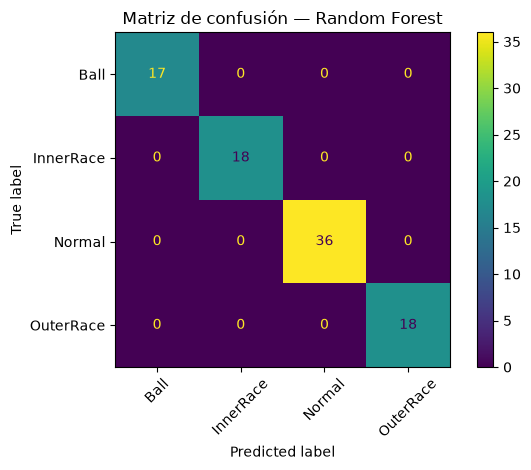

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_rf,
    xticks_rotation=45
)
plt.title("Matriz de confusión — Random Forest")
plt.tight_layout()
plt.show()

## 16. ¿Qué características utiliza más el Random Forest?

La importancia no significa causalidad, pero ayuda a entender qué variables contribuyeron más a las decisiones del modelo.

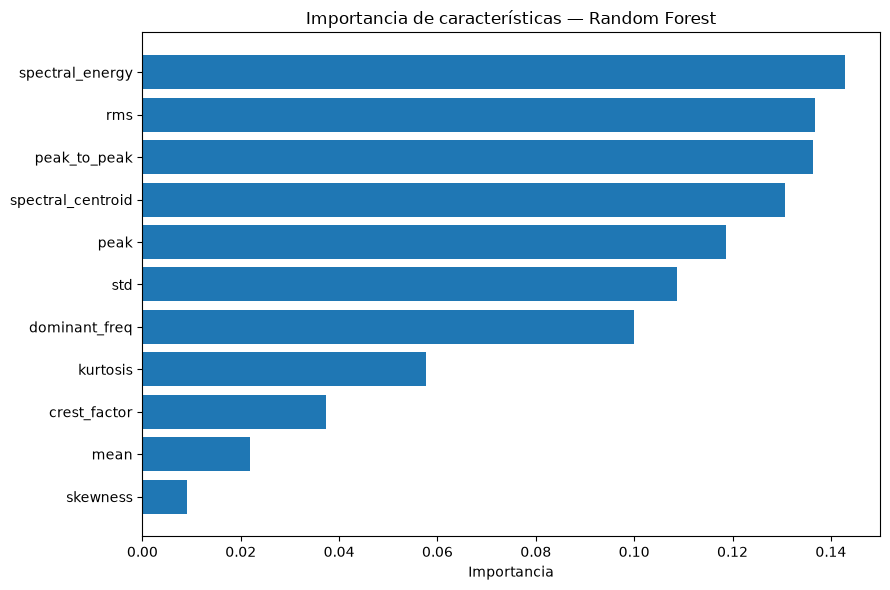

spectral_energy      0.142850
rms                  0.136695
peak_to_peak         0.136376
spectral_centroid    0.130734
peak                 0.118589
std                  0.108756
dominant_freq        0.099959
kurtosis             0.057750
crest_factor         0.037432
mean                 0.021889
skewness             0.008970
dtype: float64

In [19]:
importance = (
    pd.Series(rf_model.feature_importances_, index=feature_cols)
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 6))
plt.barh(importance.index, importance.values)
plt.xlabel("Importancia")
plt.title("Importancia de características — Random Forest")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False)

## 17. Comparación sencilla de modelos

In [20]:
results = pd.DataFrame({
    "Modelo": ["Regresión logística", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, pred_log),
        accuracy_score(y_test, pred_rf)
    ]
})

results

,Modelo,Accuracy
0,Regresión logística,1.0
1,Random Forest,1.0


## 18. Probar una ventana individual

Simulemos ahora el caso de una nueva medición de vibración.

Tomaremos una ventana que el modelo no utilizó explícitamente como entrada individual y observaremos la predicción.

In [21]:
sample = X_test.iloc[[0]]
real_class = y_test.iloc[0]
predicted_class = rf_model.predict(sample)[0]
probabilities = rf_model.predict_proba(sample)[0]

print("Clase real:", real_class)
print("Predicción:", predicted_class)
print()

proba_df = pd.DataFrame({
    "Clase": rf_model.classes_,
    "Probabilidad": probabilities
}).sort_values("Probabilidad", ascending=False)

proba_df

Clase real: Normal
Predicción: Normal



,Clase,Probabilidad
2,Normal,1.0
0,Ball,0.0
1,InnerRace,0.0
3,OuterRace,0.0


## 19. Punto metodológico importante: riesgo de fuga de información

En esta práctica, muchas ventanas provienen del **mismo registro original**.

Esto significa que ventanas del mismo archivo pueden terminar tanto en entrenamiento como en prueba.

Para una práctica esto permite mostrar claramente el flujo completo de ML, pero **no es el protocolo experimental más riguroso**.

En un proyecto real conviene separar los datos por:

- archivo,
- ensayo,
- máquina,
- carga,
- o condición experimental,

antes de crear las ventanas.

De ese modo se evalúa si el modelo generaliza a señales realmente nuevas y no solamente a segmentos muy parecidos de un mismo registro.

## 20. Actividad práctica:

### Parte A — interpretación
Responder:

1. ¿Qué representa una muestra de la señal?
2. ¿Qué significa una frecuencia de muestreo de 12 kHz?
3. ¿Por qué segmentamos la señal en ventanas?
4. ¿Qué diferencia existe entre la señal cruda y las características?
5. ¿Qué representa RMS?
6. ¿Por qué la curtosis puede ser útil en fallas de rodamientos?
7. ¿Qué información aporta la FFT?
8. ¿Qué representa una matriz de confusión?
9. ¿Qué significa que una característica tenga alta importancia en Random Forest?
10. ¿Por qué podría existir fuga de información si ventanas del mismo archivo aparecen en entrenamiento y prueba?

### Parte B — modificación del código
Cada grupo debe modificar **una** de las siguientes condiciones:

- cambiar el tamaño de ventana de 2048 a 1024;
- agregar 50 % de solapamiento;
- eliminar las características de frecuencia;
- entrenar solamente con características temporales;
- comparar Random Forest con SVM (u otro modelo que desee experimentar);
- cambiar el tamaño del conjunto de prueba.

Luego deberá explicar cómo cambia el resultado y por qué.

## 20.A Respuestas — Parte A (interpretación)

**1. ¿Qué representa una muestra de la señal?**

Es el valor de aceleración que midió el acelerómetro del *Drive End* en un instante concreto, $t_i = i / f_s$ (en unidades de g). La señal es la sucesión de esas lecturas. Por ejemplo, el registro `Normal` tiene 243.938 muestras, es decir, $243938 / 12000 \approx 20{,}3$ s de vibración. Una sola muestra no dice nada sobre el estado del rodamiento: la información aparece en cómo varían muchas muestras seguidas.

**2. ¿Qué significa una frecuencia de muestreo de 12 kHz?**

Que se toman 12.000 muestras por segundo, una cada $1/12000 \approx 83{,}3\ \mu s$. Por el teorema de Nyquist, la frecuencia más alta que se puede representar sin *aliasing* es $f_s/2 = 6$ kHz. Ese ancho de banda cubre de sobra el giro del eje (~30 Hz a 1797 rpm) y las frecuencias características de defecto del rodamiento (~100–170 Hz) con sus armónicos. También cubre buena parte de las resonancias estructurales (kHz) que excitan los impactos.

**3. ¿Por qué segmentamos la señal en ventanas?**

- **Para tener muchos ejemplos:** con 4 archivos tendríamos 4 filas; con ventanas de 2048 muestras obtenemos 296.
- **Para que cada ejemplo tenga longitud fija:** los modelos clásicos necesitan el mismo número de variables por fila.
- **Porque cada ventana ya contiene el patrón de falla:** 2048 muestras son ~0,171 s, unas 5 vueltas del eje y entre 18 y 28 impactos de defecto. Además, en tan poco tiempo la señal es aproximadamente estacionaria.
- **Para imitar el uso real:** un sistema de monitoreo diagnostica por bloques, a medida que llegan los datos.
- **Hay un compromiso:** con ventanas más largas mejora la resolución en frecuencia ($\Delta f = f_s/N = 5{,}86$ Hz para N = 2048), pero salen menos ejemplos y menos resolución en el tiempo.

**4. ¿Qué diferencia existe entre la señal cruda y las características?**

La ventana cruda son 2048 valores muy ruidosos que dependen de la fase. Si desplazamos la ventana unas pocas muestras, el vector cambia por completo aunque el estado del rodamiento sea el mismo. Las características son 11 números que resumen la ventana (energía, impulsividad, forma, contenido espectral). Son casi invariantes a ese desplazamiento y tienen significado físico. Reducen la dimensión unas 186 veces, y eso permite entrenar modelos simples con pocos datos. El costo es que se pierde toda información que esas 11 variables no capturen; por eso su diseño requiere conocer el fenómeno físico.

**5. ¿Qué representa RMS?**

Es el valor eficaz de la señal, es decir, su nivel de energía o intensidad media de vibración. Como la media de la señal es casi cero, en la tabla `rms` ≈ `std`. Es el indicador clásico de severidad global; las normas ISO de vibración usan el RMS de velocidad. Un defecto suele aumentarlo, pero el RMS **no dice qué tipo de falla hay**, y además cambia con la carga y la velocidad, no solo con el daño.

**6. ¿Por qué la curtosis puede ser útil en fallas de rodamientos?**

La curtosis (momento de 4.º orden normalizado) mide cuán "pesadas" son las colas de la distribución, es decir, cuán **impulsiva** es la señal. Una señal gaussiana tiene curtosis 3 con `fisher=False`, que es la definición usada en el código. Las ventanas `Normal` dan ~2,8–2,95, muy cerca de ese valor. Un defecto localizado (una picadura en una pista o en una bola) produce un golpe breve cada vez que un elemento rodante pasa sobre él. Esos picos aislados disparan la curtosis por encima de 3 aunque el RMS cambie poco, y por eso sirve para la **detección temprana**. Una limitación: en etapas avanzadas, cuando el daño se extiende, la señal vuelve a parecer ruido y la curtosis puede bajar. Lo mismo pasa con el *crest factor*.

**7. ¿Qué información aporta la FFT?**

Descompone la señal en componentes sinusoidales y muestra **en qué frecuencias está la energía**. En maquinaria rotativa muchos fenómenos son periódicos:

- el giro del eje (1× ≈ 30 Hz) y sus armónicos;
- las frecuencias de defecto del rodamiento 6205 a 1797 rpm: pista exterior BPFO ≈ 107 Hz, pista interior BPFI ≈ 162 Hz y bola BSF ≈ 141 Hz;
- las resonancias estructurales de alta frecuencia que excitan los impactos.

Por eso la **frecuencia dominante** y el **centroide espectral** separan las clases: las fallas desplazan energía hacia frecuencias altas. La FFT tiene dos limitaciones: pierde la información temporal y su resolución está limitada por la longitud de la ventana. Las frecuencias de defecto suelen verse mejor con un análisis de envolvente.

**8. ¿Qué representa una matriz de confusión?**

Es una tabla de clase real (filas) contra clase predicha (columnas). La diagonal son los aciertos; cada celda fuera de la diagonal indica **qué clase se confunde con cuál**. Es más informativa que la accuracy por dos motivos:

- **Los errores no cuestan lo mismo:** en mantenimiento, predecir `Normal` cuando hay falla (falla no detectada) es mucho más caro que una falsa alarma.
- **Las clases están desbalanceadas:** 119 ventanas `Normal` contra 59 de cada falla.

En este taller la matriz es diagonal pura (accuracy = 1,0). En la Parte B aparece un caso con errores reales.

**9. ¿Qué significa que una característica tenga alta importancia en Random Forest?**

Que, en promedio sobre los 300 árboles, las divisiones que usan esa variable redujeron mucho la impureza (Gini), ponderado por la cantidad de muestras que pasan por cada nodo. En otras palabras, el modelo **se apoyó mucho en ella** para separar las clases (los valores suman 1). Hay que leerla con cuidado:

- **No implica causalidad** ni que la variable sea imprescindible.
- **Las variables correlacionadas se reparten la importancia:** `std`, `rms`, `peak`, `peak_to_peak` y `spectral_energy` miden casi lo mismo.
- **Se calcula sobre el entrenamiento.** Una alternativa más robusta es la *permutation importance* sobre el conjunto de prueba.

**10. ¿Por qué podría existir fuga de información si ventanas del mismo archivo aparecen en entrenamiento y prueba?**

Las ventanas de un mismo registro comparten el motor, la carga, el montaje del sensor, el ruido de fondo y el estado exacto del daño. Por eso una ventana de prueba es casi una "copia" de las de entrenamiento, y el modelo puede acertar reconociendo la **huella del archivo** en vez de la falla. Acá el problema es extremo: **cada clase es un único archivo**, así que "clase" y "archivo" son lo mismo, y un modelo que identifique el archivo saca 100 %. Por eso la accuracy de 1,0 es optimista: mide interpolación dentro de registros ya vistos, no generalización a señales nuevas. Si además las ventanas se solapan, comparten literalmente muestras, que es justo lo que analiza la Parte B.

## 20.B Parte B — Opción elegida: **agregar 50 % de solapamiento**

Elegimos esta opción porque, a primera vista, parece una mejora gratuita: con la misma señal se obtiene el doble de ventanas. Pero se conecta directamente con la fuga de información (pregunta 10 y sección 19).

**Hipótesis:**

1. El solapamiento duplica las filas, pero **no agrega información nueva**: cada ventana comparte la mitad de sus muestras con la vecina.
2. Con una división aleatoria, casi todas las ventanas de prueba van a compartir muestras con alguna de entrenamiento. La evaluación queda contaminada, aunque la accuracy no lo muestre.
3. Para medir el efecto real hay que evaluar con un protocolo honesto: división temporal y registros nuevos (otra carga, otro tamaño de defecto).

Comparamos siempre dos versiones del dataset: **sin solapamiento** (`step = 2048`, la original) y **con 50 % de solapamiento** (`step = 1024`).

In [22]:
STEP_SOLAPADO = WINDOW_SIZE // 2  # 50 % de solapamiento


def build_dataset(signals, window_size=WINDOW_SIZE, step=STEP):
    """Ventanas -> características, guardando dónde empieza cada ventana."""
    rows = []
    for label, x in signals.items():
        for start in range(0, len(x) - window_size + 1, step):
            features = extract_features(x[start:start + window_size])
            features["label"] = label
            features["start"] = start
            features["n_signal"] = len(x)
            rows.append(features)
    return pd.DataFrame(rows)


datasets = {
    "Sin solapamiento": build_dataset(signals, step=STEP),
    "Solapamiento 50 %": build_dataset(signals, step=STEP_SOLAPADO),
}

conteo = pd.DataFrame({nombre: d.groupby("label").size() for nombre, d in datasets.items()}).T
conteo["Total"] = conteo.sum(axis=1)
conteo

label,Ball,InnerRace,Normal,OuterRace,Total
Sin solapamiento,59,59,119,59,296
Solapamiento 50 %,118,117,237,118,590


### B.1 Herramientas de evaluación

- `evaluate` entrena los dos modelos del taller (regresión logística y Random Forest) y devuelve la accuracy y el F1 macro. El F1 macro castiga más los errores en las clases minoritarias.
- `fuga` calcula qué fracción de las ventanas de prueba **comparte al menos una muestra** con alguna ventana de entrenamiento del mismo registro.

In [23]:
from sklearn.metrics import f1_score


def make_models():
    return {
        "Regresión logística": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=3000)),
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE
        ),
    }


def evaluate(df_train, df_test):
    results = {}
    fitted = {}
    for name, model in make_models().items():
        model.fit(df_train[feature_cols], df_train["label"])
        pred = model.predict(df_test[feature_cols])
        results[name] = {
            "Accuracy": accuracy_score(df_test["label"], pred),
            "F1 macro": f1_score(df_test["label"], pred, average="macro"),
        }
        fitted[name] = (model, pred)
    return results, fitted


def fuga(df_train, df_test, window_size=WINDOW_SIZE):
    """Fracción de ventanas de prueba que comparten muestras con el entrenamiento."""
    compartidas = 0
    for label, g in df_test.groupby("label"):
        starts_train = df_train.loc[df_train["label"] == label, "start"].values
        for s in g["start"]:
            if np.any(np.abs(starts_train - s) < window_size):
                compartidas += 1
    return compartidas / len(df_test)


def results_table(rows):
    table = []
    for escenario, dataset, res, extra in rows:
        for modelo, m in res.items():
            table.append({"Escenario": escenario, "Dataset": dataset,
                          "Modelo": modelo, **m, **extra})
    return pd.DataFrame(table)

### B.2 Escenario 1 — División aleatoria (protocolo original del taller)

Repetimos el `train_test_split` aleatorio 70/30 estratificado del taller, con y sin solapamiento.

In [24]:
rows = []

for nombre, d in datasets.items():
    tr, te = train_test_split(
        d, test_size=0.30, random_state=RANDOM_STATE, stratify=d["label"]
    )
    res, _ = evaluate(tr, te)
    rows.append(("1. Aleatoria", nombre, res, {
        "n_train": len(tr), "n_test": len(te),
        "% test con fuga": round(100 * fuga(tr, te), 1),
    }))

tabla_random = results_table(rows)
tabla_random

,Escenario,Dataset,Modelo,Accuracy,F1 macro,n_train,n_test,% test con fuga
0,1. Aleatoria,Sin solapamiento,Regresión logística,1.0,1.0,207,89,0.0
1,1. Aleatoria,Sin solapamiento,Random Forest,1.0,1.0,207,89,0.0
2,1. Aleatoria,Solapamiento 50 %,Regresión logística,1.0,1.0,413,177,93.8
3,1. Aleatoria,Solapamiento 50 %,Random Forest,1.0,1.0,413,177,93.8


**Observación:** con solapamiento, la accuracy sigue en 1,0, pero la gran mayoría de las ventanas de prueba comparte la mitad (o más) de sus muestras con alguna ventana de entrenamiento. Parte de lo que llamamos "prueba" es literalmente la misma señal que vio el modelo. **La métrica no cambia, y justamente por eso no sirve para detectar la fuga**: hay que diseñar un protocolo que la impida.

### B.3 Escenario 2 — División temporal (sin muestras compartidas)

Para cada registro, el **primer 70 % de la señal** va a entrenamiento y el **último 30 %** a prueba. Se descartan las ventanas que cruzan el corte, así que ninguna ventana de prueba comparte muestras con el entrenamiento. Esto imita el uso real: se entrena con el pasado y se predice el futuro.

In [25]:
def temporal_split(d, frac=0.70, window_size=WINDOW_SIZE):
    cut = (d["n_signal"] * frac).astype(int)
    train = d[d["start"] + window_size <= cut]
    test = d[d["start"] >= cut]
    return train, test


rows = []
for nombre, d in datasets.items():
    tr, te = temporal_split(d)
    res, _ = evaluate(tr, te)
    rows.append(("2. Temporal", nombre, res, {
        "n_train": len(tr), "n_test": len(te),
        "% test con fuga": round(100 * fuga(tr, te), 1),
    }))

tabla_temporal = results_table(rows)
tabla_temporal

,Escenario,Dataset,Modelo,Accuracy,F1 macro,n_train,n_test,% test con fuga
0,2. Temporal,Sin solapamiento,Regresión logística,1.0,1.0,206,86,0.0
1,2. Temporal,Sin solapamiento,Random Forest,1.0,1.0,206,86,0.0
2,2. Temporal,Solapamiento 50 %,Regresión logística,1.0,1.0,410,172,0.0
3,2. Temporal,Solapamiento 50 %,Random Forest,1.0,1.0,410,172,0.0


### B.4 Escenario 3 — Registros completamente nuevos

La división temporal elimina las muestras compartidas, pero el entrenamiento y la prueba siguen saliendo **del mismo ensayo**. La prueba más exigente es la que propone la sección 19: entrenar con todos los registros del taller (carga 0 HP, defectos de 0,007") y evaluar con **otros archivos del CWRU** que el modelo nunca vio:

| Escenario | Normal | InnerRace | Ball | OuterRace |
|---|---:|---:|---:|---:|
| Otra carga: 1 HP (defecto 0,007") | 98.mat | 106.mat | 119.mat | 131.mat |
| Otra carga: 3 HP (defecto 0,007") | 100.mat | 108.mat | 121.mat | 133.mat |
| Otro tamaño de defecto: 0,014" (0 HP) | 98.mat* | 169.mat | 185.mat | 197.mat |

\* No hay un registro "Normal" de 0,014", porque el normal no tiene defecto. Usamos el normal de 1 HP para que también sea un archivo no visto.

Los conjuntos de prueba se arman **siempre sin solapamiento**, así ambas versiones se evalúan sobre exactamente las mismas ventanas. Lo único que cambia es cómo se construyó el entrenamiento.

In [26]:
files_nuevos = {
    "Carga 1 HP": {"Normal": "98.mat", "InnerRace": "106.mat",
                   "Ball": "119.mat", "OuterRace": "131.mat"},
    "Carga 3 HP": {"Normal": "100.mat", "InnerRace": "108.mat",
                   "Ball": "121.mat", "OuterRace": "133.mat"},
    'Defecto 0,014"': {"Normal": "98.mat", "InnerRace": "169.mat",
                       "Ball": "185.mat", "OuterRace": "197.mat"},
}

for escenario in files_nuevos.values():
    for filename in escenario.values():
        path = os.path.join("cwru_data", filename)
        if not os.path.exists(path):
            print("Descargando", filename)
            urllib.request.urlretrieve(BASE_URL + filename, path)

test_nuevos = {
    escenario: build_dataset(
        {label: load_de_signal(os.path.join("cwru_data", f))
         for label, f in archivos.items()},
        step=STEP,
    )
    for escenario, archivos in files_nuevos.items()
}

{escenario: len(d) for escenario, d in test_nuevos.items()}

{'Carga 1 HP': 413, 'Carga 3 HP': 415, 'Defecto 0,014"': 413}

In [27]:
rows = []
modelos_014 = {}

for escenario, te in test_nuevos.items():
    for nombre, d in datasets.items():
        res, fitted = evaluate(d, te)
        rows.append((f"3. {escenario}", nombre, res, {
            "n_train": len(d), "n_test": len(te), "% test con fuga": 0.0,
        }))
        if escenario.startswith("Defecto"):
            modelos_014[nombre] = fitted

tabla_nuevos = results_table(rows)
tabla_nuevos

,Escenario,Dataset,Modelo,Accuracy,F1 macro,n_train,n_test,% test con fuga
0,3. Carga 1 HP,Sin solapamiento,Regresión logística,1.000000,1.000000,296,413,0.0
1,3. Carga 1 HP,Sin solapamiento,Random Forest,1.000000,1.000000,296,413,0.0
2,3. Carga 1 HP,Solapamiento 50 %,Regresión logística,1.000000,1.000000,590,413,0.0
3,3. Carga 1 HP,Solapamiento 50 %,Random Forest,1.000000,1.000000,590,413,0.0
4,3. Carga 3 HP,Sin solapamiento,Regresión logística,0.915663,0.841367,296,415,0.0
5,3. Carga 3 HP,Sin solapamiento,Random Forest,1.000000,1.000000,296,415,0.0
6,3. Carga 3 HP,Solapamiento 50 %,Regresión logística,0.920482,0.851833,590,415,0.0
7,3. Carga 3 HP,Solapamiento 50 %,Random Forest,1.000000,1.000000,590,415,0.0
8,"3. Defecto 0,014""",Sin solapamiento,Regresión logística,0.699758,0.420291,296,413,0.0
9,"3. Defecto 0,014""",Sin solapamiento,Random Forest,0.631961,0.308265,296,413,0.0


### B.5 Resumen de todos los escenarios

Dataset                                Sin solapamiento  Solapamiento 50 %  \
Escenario         Modelo                                                     
1. Aleatoria      Random Forest                   1.000               1.00   
                  Regresión logística             1.000               1.00   
2. Temporal       Random Forest                   1.000               1.00   
                  Regresión logística             1.000               1.00   
3. Carga 1 HP     Random Forest                   1.000               1.00   
                  Regresión logística             1.000               1.00   
3. Carga 3 HP     Random Forest                   1.000               1.00   
                  Regresión logística             0.916               0.92   
3. Defecto 0,014" Random Forest                   0.632               0.63   
                  Regresión logística             0.700               0.70   

Dataset                                Diferencia  
Escenario         Modelo                           
1. Aleatoria      Random Forest             0.000  
                  Regresión logística       0.000  
2. Temporal       Random Forest             0.000  
                  Regresión logística       0.000  
3. Carga 1 HP     Random Forest             0.000  
                  Regresión logística       0.000  
3. Carga 3 HP     Random Forest             0.000  
                  Regresión logística       0.005  
3. Defecto 0,014" Random Forest            -0.002  
                  Regresión logística       0.000

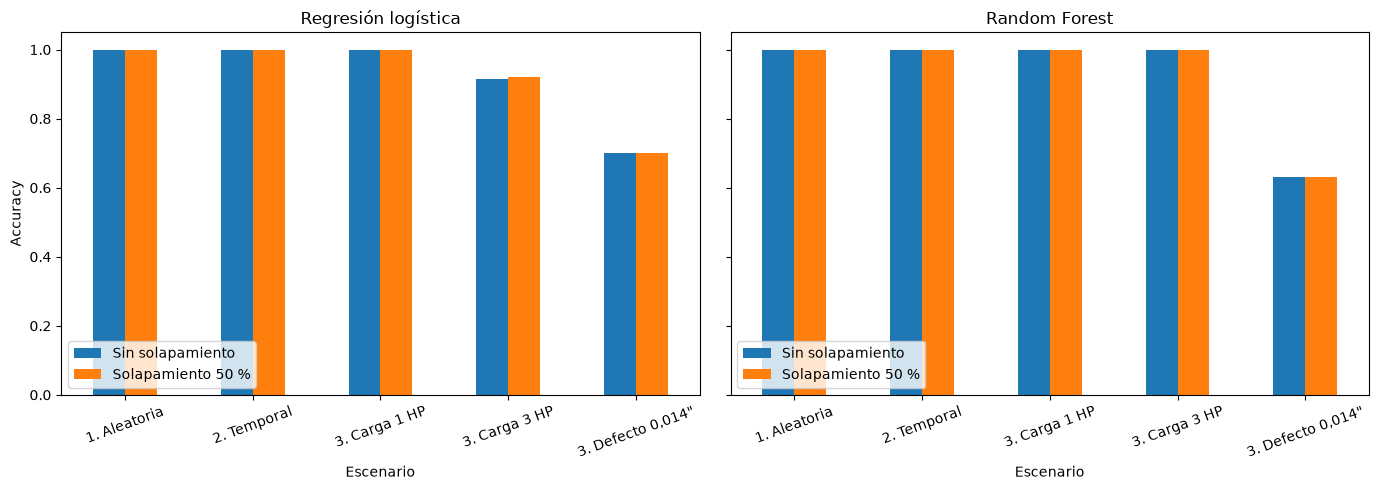

In [28]:
resumen = pd.concat([tabla_random, tabla_temporal, tabla_nuevos], ignore_index=True)

pivot = resumen.pivot_table(
    index=["Escenario", "Modelo"], columns="Dataset", values="Accuracy"
)
pivot["Diferencia"] = pivot["Solapamiento 50 %"] - pivot["Sin solapamiento"]
display(pivot.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, modelo in zip(axes, ["Regresión logística", "Random Forest"]):
    sub = pivot.xs(modelo, level="Modelo")[["Sin solapamiento", "Solapamiento 50 %"]]
    sub.plot.bar(ax=ax, rot=20)
    ax.set_title(modelo)
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### B.6 ¿Dónde falla el modelo con el defecto no visto?

La matriz de confusión del escenario más difícil (defecto de 0,014") muestra qué tipo de error comete cada modelo entrenado con solapamiento.

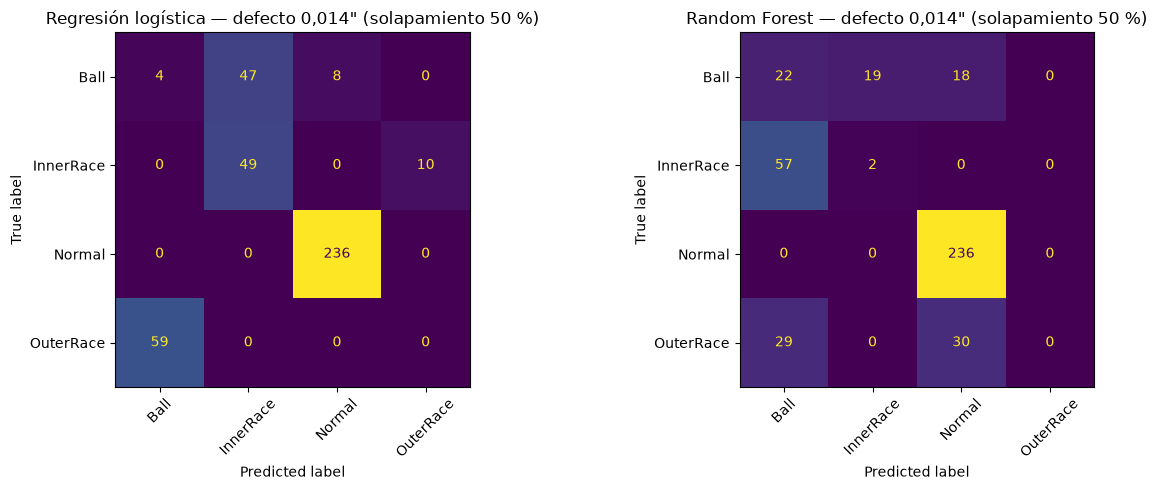

In [29]:
te = test_nuevos['Defecto 0,014"']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (modelo, (_, pred)) in zip(axes, modelos_014["Solapamiento 50 %"].items()):
    ConfusionMatrixDisplay.from_predictions(
        te["label"], pred, ax=ax, xticks_rotation=45, colorbar=False
    )
    ax.set_title(f'{modelo} — defecto 0,014" (solapamiento 50 %)')
plt.tight_layout()
plt.show()

### B.7 Conclusiones — ¿cómo cambió el resultado y por qué?

| Escenario | Fuga (sin / con solap.) | LogReg (sin → con) | RF (sin → con) |
|---|---:|---:|---:|
| 1. División aleatoria | 0 % / **93,8 %** | 1,000 → 1,000 | 1,000 → 1,000 |
| 2. División temporal | 0 % / 0 % | 1,000 → 1,000 | 1,000 → 1,000 |
| 3. Carga 1 HP (archivos nuevos) | 0 % / 0 % | 1,000 → 1,000 | 1,000 → 1,000 |
| 3. Carga 3 HP (archivos nuevos) | 0 % / 0 % | 0,916 → 0,920 | 1,000 → 1,000 |
| 3. Defecto 0,014" (archivos nuevos) | 0 % / 0 % | 0,700 → 0,700 | 0,632 → 0,630 |

**1. El solapamiento duplicó los datos, pero no la información.** Pasamos de 296 a 590 ventanas, aunque cada ventana nueva es mitad de la anterior y mitad de la siguiente. Son filas muy correlacionadas, no observaciones independientes. Por eso, en todos los escenarios honestos la accuracy cambia como mucho ±0,005 (2 ventanas de 415). Esa diferencia es ruido, no una mejora.

**2. Con la división aleatoria, el solapamiento genera fuga masiva, y la accuracy no la detecta.** El 93,8 % de las ventanas de prueba comparte muestras con el entrenamiento. Aun así la métrica no cambia, porque ya estaba en 1,0. Esta es la lección central: **una métrica perfecta no prueba que la evaluación sea válida**. Si el problema fuera más difícil, esa fuga inflaría la accuracy y nos haría creer que el solapamiento "mejoró" el modelo. En la práctica, cuando se usan ventanas solapadas, la división siempre tiene que hacerse **antes** de ventanear (por tiempo, por archivo o por ensayo).

**3. Este problema es demasiado fácil para medir efectos finos.** Con 4 archivos y una clase por archivo, los modelos aciertan el 100 % incluso entrenando con 0 HP y probando con 1 HP. Las fallas de 0,007" a 0 HP tienen firmas (RMS, curtosis, centroide) muy distintas entre sí.

**4. El verdadero límite es la diversidad de condiciones, no la cantidad de ventanas.** El rendimiento se desploma cuando aparece un tamaño de defecto que el modelo no vio (0,014"):

- **Accuracy:** 0,63 (RF) y 0,70 (regresión logística).
- **F1 macro:** solo 0,31 y 0,42, porque las 236 ventanas `Normal` se clasifican bien e inflan la accuracy.
- **Errores entre fallas:** la regresión logística manda todas las ventanas de pista exterior a `Ball` y casi todas las de bola a `InnerRace`. Random Forest manda 57 de 59 ventanas de pista interior a `Ball`.
- **Fallas no detectadas (lo más grave):** Random Forest predice `Normal` en ~48 ventanas que tienen falla (30 de pista exterior y 18 de bola).

Con más defecto, el RMS, la curtosis y el espectro caen en zonas del espacio de características que el entrenamiento nunca cubrió, y **duplicar ventanas del mismo registro no agrega ese conocimiento**.

**Respuesta final:** agregar 50 % de solapamiento **no cambió el resultado** en ningún escenario evaluado honestamente. La razón es que no aporta información nueva: solo repite, desplazada, la que ya había. Con una división aleatoria, además, **contamina la evaluación** (93,8 % de fuga) sin que la accuracy lo revele. El solapamiento puede ser útil como *data augmentation* cuando hay muy poca señal y modelos que necesitan muchos ejemplos (por ejemplo, redes neuronales sobre la señal cruda). Pero para mejorar la generalización hay que sumar **registros de condiciones distintas** (cargas, tamaños de defecto, máquinas) y evaluar siempre separando por registro.

## 21. Resumen de la práctica

El flujo completo fue:

**Acelerómetro → señal de vibración → segmentación → extracción de características → dataset tabular → entrenamiento → evaluación → interpretación**

La idea central no es memorizar el código, sino comprender que un problema de IA industrial exige conectar tres dominios:

1. **Fenómeno físico**
2. **Procesamiento de señales**
3. **Machine Learning**